In [1]:
# Data handling
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve
)

# Models
from sklearn.ensemble import RandomForestClassifier

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
import os

# Display available files
print("Files in project folder:")
print(os.listdir())

Files in project folder:
['prediction.ipynb', 'Telco-Customer-Churn.csv']


In [3]:
df = pd.read_csv("Telco-Customer-Churn.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  704

In [5]:
# Remove customerID because it is not useful for prediction
df.drop("customerID", axis=1, inplace=True)

# Convert TotalCharges into numeric format
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# Check missing values after conversion
print("Missing values after conversion:")
print(df.isnull().sum())

# Fill missing TotalCharges with median
df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())

print("\nData cleaning completed!")
print("New Dataset Shape:", df.shape)

Missing values after conversion:
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

Data cleaning completed!
New Dataset Shape: (7043, 20)


Customer Churn Distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


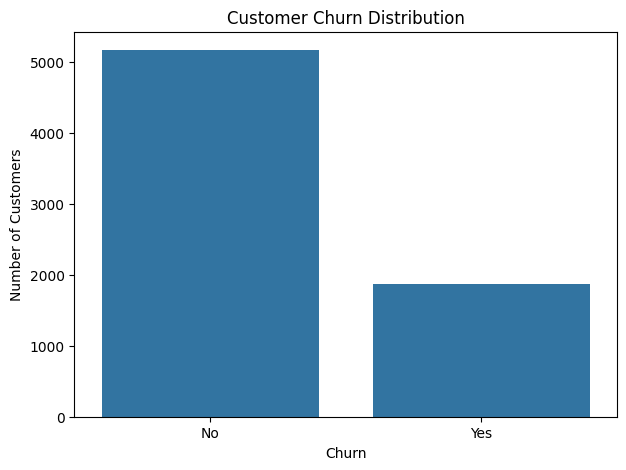

In [6]:
# Count customers in each churn category
print("Customer Churn Distribution:")
print(df["Churn"].value_counts())

# Visualize churn distribution
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

In [7]:
churn_percentage = df["Churn"].value_counts(normalize=True) * 100

print("Churn Percentage:")
print(churn_percentage.round(2))

Churn Percentage:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


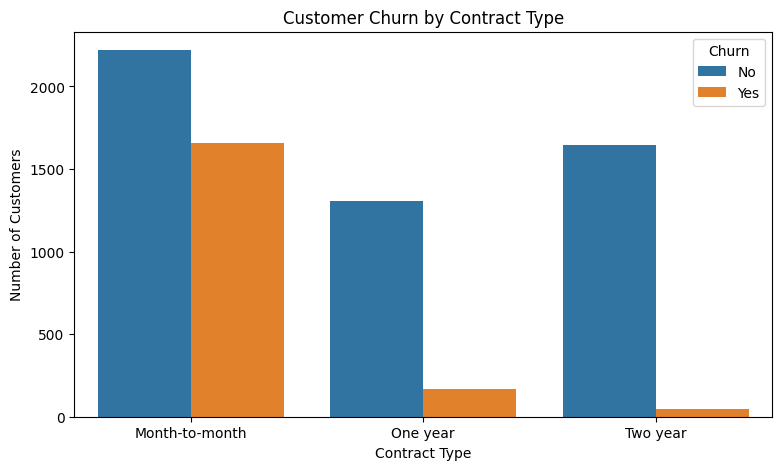

In [8]:
# Analyze churn by contract type

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Contract",
    hue="Churn"
)

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")

plt.show()

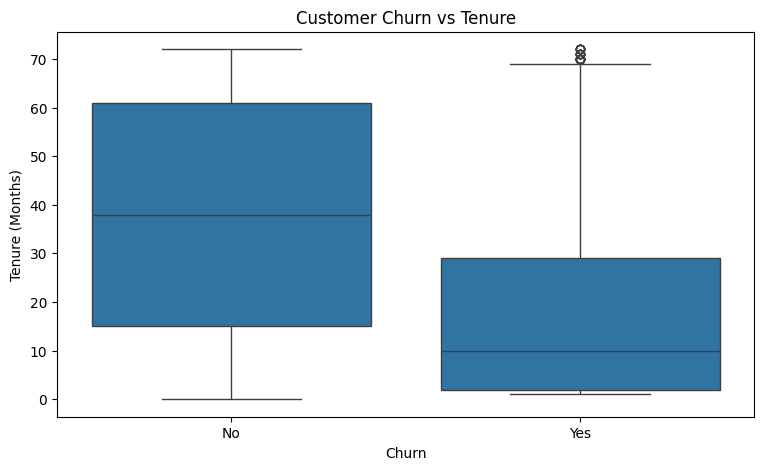

In [9]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure"
)

plt.title("Customer Churn vs Tenure")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")

plt.show()

In [10]:
# Separate features and target

X = df.drop("Churn", axis=1)
y = df["Churn"]

# Convert target into numerical values
y = y.map({"No": 0, "Yes": 1})

# Identify categorical and numerical columns

categorical_features = X.select_dtypes(include=["object"]).columns
numerical_features = X.select_dtypes(exclude=["object"]).columns

print("Categorical Features:")
print(list(categorical_features))

print("\nNumerical Features:")
print(list(numerical_features))

print("\nTarget Distribution:")
print(y.value_counts())

Categorical Features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Numerical Features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Target Distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [11]:
# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

Training Data Shape: (5634, 19)
Testing Data Shape: (1409, 19)

Training Target Distribution:
Churn
0    4139
1    1495
Name: count, dtype: int64

Testing Target Distribution:
Churn
0    1035
1     374
Name: count, dtype: int64


In [12]:
# Create preprocessing pipeline

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("num", "passthrough", numerical_features)
    ]
)

# Apply encoding
X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)

print("Encoding completed successfully!")

print("Training Data Shape:", X_train_encoded.shape)
print("Testing Data Shape:", X_test_encoded.shape)

Encoding completed successfully!
Training Data Shape: (5634, 45)
Testing Data Shape: (1409, 45)


In [13]:
# Import Random Forest
from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42
)

# Train the model
rf_model.fit(X_train_encoded, y_train)

print("Random Forest Model trained successfully!")

Random Forest Model trained successfully!


In [14]:
# Predict customer churn
y_pred_rf = rf_model.predict(X_test_encoded)

# Predict probabilities
y_prob_rf = rf_model.predict_proba(X_test_encoded)[:, 1]

print("Predictions completed successfully!")

print("\nFirst 10 Predictions:")
print(y_pred_rf[:10])

Predictions completed successfully!

First 10 Predictions:
[0 1 0 0 0 0 0 0 0 0]


In [15]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Calculate accuracy
accuracy_rf = accuracy_score(y_test, y_pred_rf)

# Calculate ROC-AUC
roc_auc_rf = roc_auc_score(y_test, y_prob_rf)

print("Random Forest Model Evaluation")
print("--------------------------------")
print("Accuracy:", round(accuracy_rf * 100, 2), "%")
print("ROC-AUC Score:", round(roc_auc_rf, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

Random Forest Model Evaluation
--------------------------------
Accuracy: 78.42 %
ROC-AUC Score: 0.822

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.89      0.86      1035
           1       0.62      0.48      0.54       374

    accuracy                           0.78      1409
   macro avg       0.72      0.69      0.70      1409
weighted avg       0.77      0.78      0.78      1409


Confusion Matrix:
[[924 111]
 [193 181]]


In [16]:
%pip install xgboost

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   - -------------------------------------- 1.3/48.9 MB 7.2 MB/s eta 0:00:07
   -- ------------------------------------- 2.9/48.9 MB 7.5 MB/s eta 0:00:07
   ---- ----------------------------------- 5.0/48.9 MB 8.3 MB/s eta 0:00:06
   ----- ---------------------------------- 6.3/48.9 MB 8.1 MB/s eta 0:00:06
   ----- ---------------------------------- 7.1/48.9 MB 7.2 MB/s eta 0:00:06
   ------ --------------------------------- 7.9/48.9 MB 6.4 MB/s eta 0:00:07
   ------ --------------------------------- 8.4/48.9 MB 5.9 MB/s eta 0:00:07
   ------- -------------------------------- 9.2/48.9 MB 5.6 MB/s eta 0:00:08
   ------- -------------------------------- 9.7/48.9 MB 5.3 MB/s eta 0:00:08
   -------- ------------------------------- 10.5/48.9 MB 5.1 MB/s eta 0:00:08
   --------

In [17]:
from xgboost import XGBClassifier

print("XGBoost imported successfully!")

XGBoost imported successfully!


In [18]:
# Create XGBoost model

xgb_model = XGBClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=len(y_train[y_train == 0]) / len(y_train[y_train == 1]),
    random_state=42,
    eval_metric="logloss"
)

# Train model
xgb_model.fit(X_train_encoded, y_train)

print("XGBoost Model trained successfully!")

XGBoost Model trained successfully!


In [19]:
# Predict customer churn
y_pred_xgb = xgb_model.predict(X_test_encoded)

# Predict probabilities
y_prob_xgb = xgb_model.predict_proba(X_test_encoded)[:, 1]

print("XGBoost predictions completed!")

print("\nFirst 10 Predictions:")
print(y_pred_xgb[:10])

XGBoost predictions completed!

First 10 Predictions:
[0 1 0 1 0 1 1 0 0 1]


In [20]:
# Calculate metrics
accuracy_xgb = accuracy_score(y_test, y_pred_xgb)
roc_auc_xgb = roc_auc_score(y_test, y_prob_xgb)

print("XGBoost Model Evaluation")
print("------------------------")
print("Accuracy:", round(accuracy_xgb * 100, 2), "%")
print("ROC-AUC Score:", round(roc_auc_xgb, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_xgb))

XGBoost Model Evaluation
------------------------
Accuracy: 75.73 %
ROC-AUC Score: 0.8443

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.75      0.82      1035
           1       0.53      0.79      0.63       374

    accuracy                           0.76      1409
   macro avg       0.72      0.77      0.73      1409
weighted avg       0.81      0.76      0.77      1409


Confusion Matrix:
[[772 263]
 [ 79 295]]


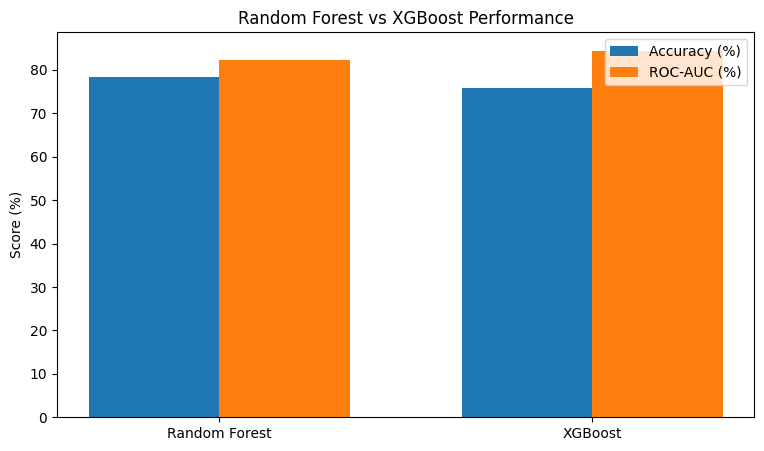

In [21]:
models = ["Random Forest", "XGBoost"]

accuracy_scores = [
    accuracy_rf * 100,
    accuracy_xgb * 100
]

roc_scores = [
    roc_auc_rf,
    roc_auc_xgb
]

plt.figure(figsize=(9, 5))

x = np.arange(len(models))
width = 0.35

plt.bar(x - width/2, accuracy_scores, width, label="Accuracy (%)")
plt.bar(x + width/2, [score * 100 for score in roc_scores],
        width, label="ROC-AUC (%)")

plt.xticks(x, models)
plt.ylabel("Score (%)")
plt.title("Random Forest vs XGBoost Performance")
plt.legend()
plt.show()

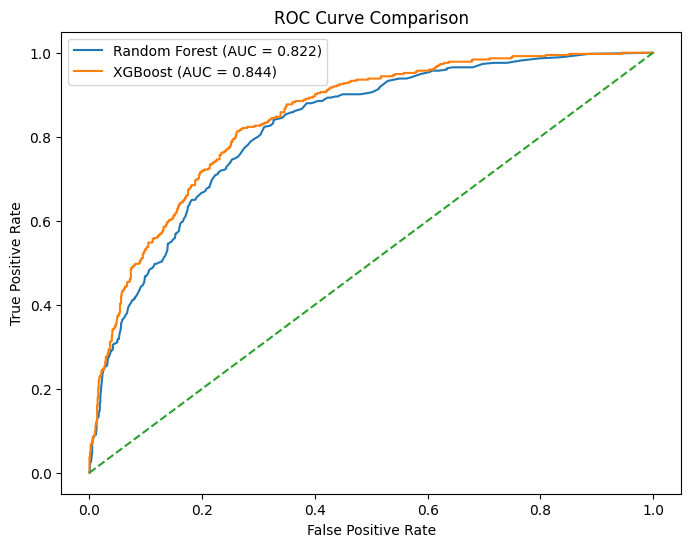

In [22]:
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_prob_xgb)

plt.figure(figsize=(8, 6))

plt.plot(fpr_rf, tpr_rf, label=f"Random Forest (AUC = {roc_auc_rf:.3f})")
plt.plot(fpr_xgb, tpr_xgb, label=f"XGBoost (AUC = {roc_auc_xgb:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")

plt.legend()
plt.show()

In [23]:
# Get feature names after One-Hot Encoding
feature_names = preprocessor.get_feature_names_out()

# Get XGBoost feature importance
importance = xgb_model.feature_importances_

# Create feature importance DataFrame
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

# Sort by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display top 15 features
print("Top 15 Important Features:")
display(feature_importance.head(15))

Top 15 Important Features:


,Feature,Importance
32,cat__Contract_Month-to-month,0.437625
12,cat__InternetService_Fiber optic,0.075740
13,cat__InternetService_No,0.048274
14,cat__OnlineSecurity_No,0.046337
23,cat__TechSupport_No,0.034841
34,cat__Contract_Two year,0.026984
31,cat__StreamingMovies_Yes,0.024143
39,cat__PaymentMethod_Electronic check,0.020686
11,cat__InternetService_DSL,0.020433
42,num__tenure,0.016058


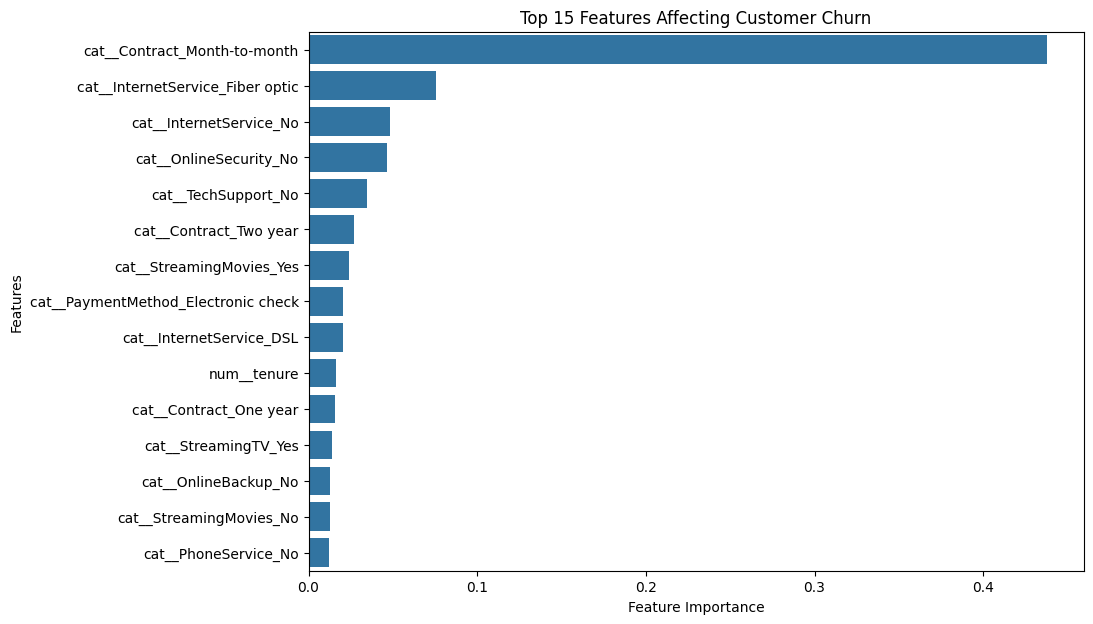

In [24]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=feature_importance.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Features Affecting Customer Churn")
plt.xlabel("Feature Importance")
plt.ylabel("Features")

plt.show()

# Project Conclusion

In this project, I developed a Customer Churn Prediction system using the Telco Customer Churn dataset containing 7,043 customer records.

### Models Implemented
- Random Forest Classifier
- XGBoost Classifier

### Best Results

**Random Forest**
- Accuracy: 78.42%
- ROC-AUC: 0.8220

**XGBoost**
- Accuracy: 75.73%
- ROC-AUC: 0.8443
- Churn Recall: 79%
- Churn F1-score: 63%

### Key Learnings
- Data cleaning and preprocessing
- Handling missing values
- One-Hot Encoding
- Handling imbalanced datasets using class weighting
- Random Forest and XGBoost
- Model evaluation using ROC-AUC
- Confusion Matrix and Feature Importance visualization

### Final Observation

XGBoost achieved a higher ROC-AUC score and better churn recall than Random Forest. Contract type was identified as the most important feature in the XGBoost model.

This project helped me understand how Machine Learning can identify customers who are likely to leave a business and support customer retention strategies.